# Residual load: overview

Residual load in the TransnetBW control area is examined over 2023–2024 to understand its level, variability, and daily, weekly, and annual patterns. Values represent energy in MWh per 15-minute interval. Calendar comparisons follow Europe/Berlin time, and the 2025 period is reserved for final testing.

Monthly, weekday, and intraday profiles show when residual load tends to be high or low. Comparing 2023 with 2024 helps assess whether these patterns remain similar across years.

## 1. Setup

In [22]:
from pathlib import Path
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display, Markdown

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/experiments/chronos2.yaml').exists())
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT / 'notebooks' / 'eda' / '01_target_overview')
CONFIG_PATH = PROJECT_ROOT / 'configs/experiments/chronos2.yaml'
config = yaml.safe_load(CONFIG_PATH.read_text(encoding='utf-8'))
data_cfg = config['data']
TARGET = 'Residual load [MWh]'
YEARS = [2023, 2024]
COLORS = ['#0072B2', '#D55E00']
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=COLORS)
plt.rcParams.update({'figure.figsize': (11, 4), 'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.options.display.float_format = '{:,.2f}'.format


## 2. Load development data

In [3]:
source = data_cfg['sources']['consumption']
raw = pd.read_csv(PROJECT_ROOT / source['development'])
dates = pd.to_datetime(raw[source['timestamp_column']], format='%b %d, %Y %I:%M %p', errors='raise')
utc = dates.dt.tz_localize(source['timezone'], ambiguous='infer').dt.tz_convert('UTC')
assert utc.notna().all() and utc.is_monotonic_increasing and not utc.duplicated().any()
values = pd.to_numeric(raw[TARGET], errors='coerce').replace([np.inf, -np.inf], np.nan)
df = pd.DataFrame({'target': values.to_numpy()}, index=pd.DatetimeIndex(utc, name='timestamp_utc'))
local = df.index.tz_convert('Europe/Berlin')
df = df.loc[local.year.isin(YEARS)].copy()
local = df.index.tz_convert('Europe/Berlin')
df['year'] = local.year
df['month'] = local.month
df['weekday'] = local.dayofweek
df['hour'] = local.hour
df['quarter_hour'] = local.hour + local.minute / 60
holidays = pd.read_csv(PROJECT_ROOT / data_cfg['sources']['holidays']['path'])
holiday_dates = pd.to_datetime(holidays['Datum']).dt.date
df['is_holiday'] = np.isin(local.date, holiday_dates).astype(int)
print(f'Source: {source["development"]}')
print(f'Target: {TARGET} | {len(df):,} intervals | Berlin years: {YEARS}')


Source: Dataset/raw/csv/Actual_consumption_2023_2024_Quarterhour.csv
Target: Residual load [MWh] | 70,176 intervals | Berlin years: [2023, 2024]


## 3. Data checks
### 3.1 Timestamp coverage

In [4]:
expected = pd.date_range(pd.Timestamp('2023-01-01', tz='Europe/Berlin').tz_convert('UTC'), pd.Timestamp('2025-01-01', tz='Europe/Berlin').tz_convert('UTC'), freq='15min', inclusive='left')
missing_intervals = expected.difference(df.index)
display(pd.Series({'observed_intervals': len(df), 'expected_intervals': len(expected), 'missing_intervals': len(missing_intervals), 'duplicate_utc_timestamps': int(df.index.duplicated().sum()), 'repeated_local_clock_times_DST': int(df.index.tz_convert('Europe/Berlin').tz_localize(None).duplicated().sum())}, name='count').to_frame())
assert len(missing_intervals) == 0

,count
observed_intervals,70176
expected_intervals,70176
missing_intervals,0
duplicate_utc_timestamps,0
repeated_local_clock_times_DST,8


### 3.2 Missing and nonfinite target values

In [5]:
display(df.groupby('year')['target'].agg(rows='size', valid='count').assign(missing=lambda t: t['rows'] - t['valid']))
print('Nonnumeric placeholders are coerced to missing. Infinite values are also treated as missing. No imputation is applied in this overview.')

,rows,valid,missing
year,,,
2023,35040,35040,0
2024,35136,35135,1


Nonnumeric placeholders are coerced to missing. Infinite values are also treated as missing. No imputation is applied in this overview.


### 3.3 Zero, negative, and extreme observations

In [6]:
display(df.groupby('year')['target'].agg(zero=lambda s: s.eq(0).sum(), negative=lambda s: s.lt(0).sum(), minimum='min', maximum='max'))
display(pd.concat([df.nsmallest(3, 'target'), df.nlargest(3, 'target')])[['target']])
print('Negative residual load can be valid. Extreme observations are retained for inspection.')

,zero,negative,minimum,maximum
year,,,,
2023,0,136,-272.50,"2,388.25"
2024,0,427,-472.00,"2,342.25"


,target
timestamp_utc,
2024-08-11 11:45:00+00:00,-472.00
2024-08-11 11:30:00+00:00,-470.75
2024-08-11 11:15:00+00:00,-468.00
2023-01-26 12:30:00+00:00,"2,388.25"
2023-01-26 12:00:00+00:00,"2,386.00"
2023-01-26 12:15:00+00:00,"2,382.50"


Negative residual load can be valid. Extreme observations are retained for inspection.


### Observations

The two-year timeline is complete in UTC. The repeated Berlin clock times occur at the autumn daylight-saving transitions, so they represent distinct physical intervals. Only one residual-load value is missing, at 23:45 Berlin time on 9 February 2024.

Negative residual load occurs in 136 intervals in 2023 and 427 in 2024, with the lowest values concentrated around midday. These observations have a physical interpretation: [SMARD defines residual load as grid load less wind and solar generation](https://www.smard.de/page/en/wiki-article/5884/6036/electricity-consumption), so negative values can occur when their combined output exceeds grid load.

## 4. Descriptive statistics
### 4.1 Overall and yearly statistics

In [7]:
statistics = pd.concat({'Overall': df['target'].describe(percentiles=[.01, .25, .5, .75, .99]), **{str(year): df.loc[df['year'].eq(year), 'target'].describe(percentiles=[.01, .25, .5, .75, .99]) for year in YEARS}}, axis=1)
display(statistics)

,Overall,2023,2024
count,"70,175.00","35,040.00","35,135.00"
mean,"1,290.80","1,300.22","1,281.41"
std,434.38,422.50,445.71
min,-472.00,-272.50,-472.00
1%,45.44,137.99,-41.41
25%,"1,046.75","1,039.75","1,052.88"
50%,"1,296.50","1,300.75","1,292.25"
75%,"1,582.25","1,585.75","1,578.50"
99%,"2,198.75","2,207.81","2,182.91"
max,"2,388.25","2,388.25","2,342.25"


### 4.2 Overall distribution

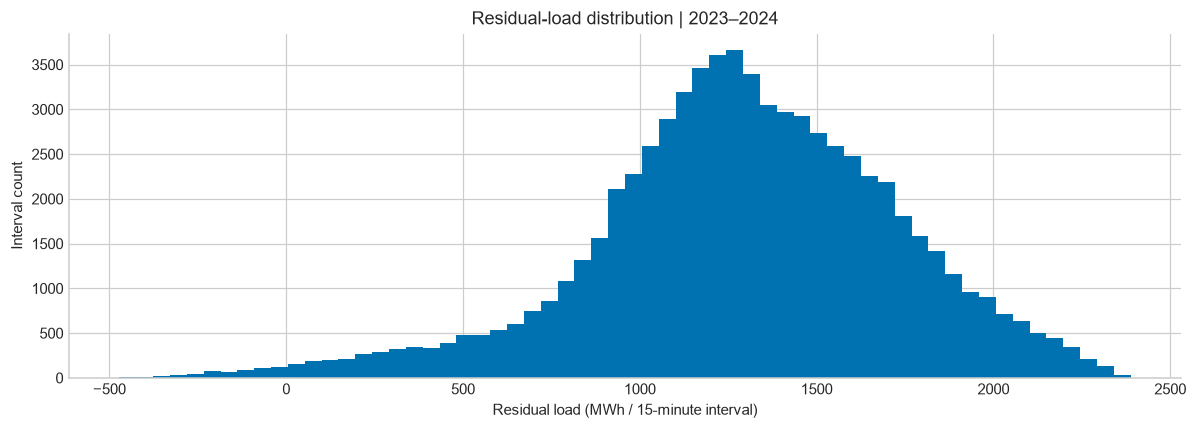

In [23]:
fig, ax = plt.subplots()
ax.hist(df['target'].dropna(), bins=60, color=COLORS[0])
ax.set(title='Residual-load distribution | 2023–2024', xlabel='Residual load (MWh / 15-minute interval)', ylabel='Interval count')
fig.tight_layout()
fig.savefig('descriptive_statistics_overall_distribution.png', dpi=160, bbox_inches='tight')
plt.show()

### Observations

Most observations cluster around 1,000–1,600 MWh per interval, with a peak near 1,250 MWh and a long lower tail extending below zero. The mean changes little between 2023 and 2024, falling from 1,300 to 1,281 MWh, while the standard deviation rises from 423 to 446 MWh. The similar averages therefore accompany greater variability and more very low residual-load intervals in 2024.

## 5. Time plots
### 5.1 Complete development period

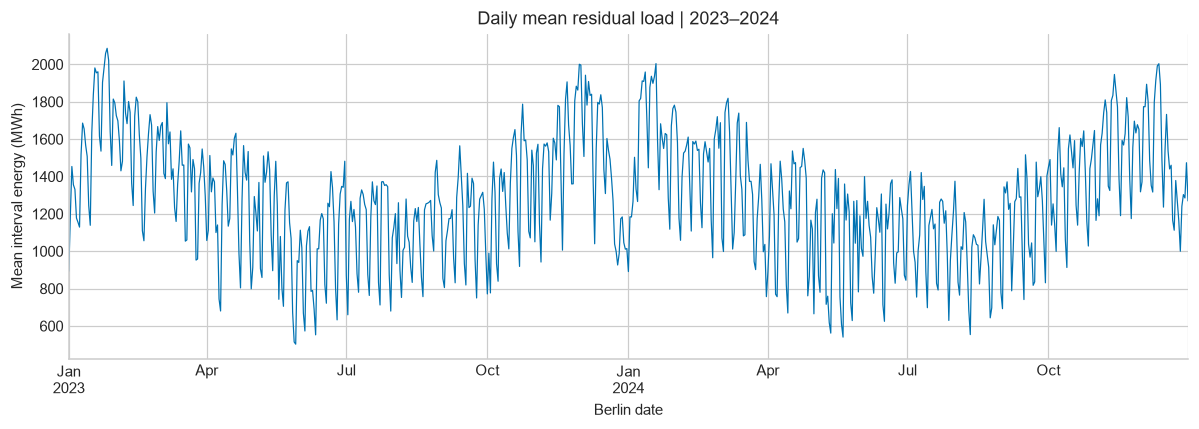

In [24]:
daily = df['target'].tz_convert('Europe/Berlin').resample('D').mean()
fig, ax = plt.subplots()
daily.plot(ax=ax, linewidth=.8, color=COLORS[0])
ax.set(title='Daily mean residual load | 2023–2024', xlabel='Berlin date', ylabel='Mean interval energy (MWh)')
fig.tight_layout()
fig.savefig('time_plots_complete_development_period.png', dpi=160, bbox_inches='tight')
plt.show()

### 5.2 Rolling mean

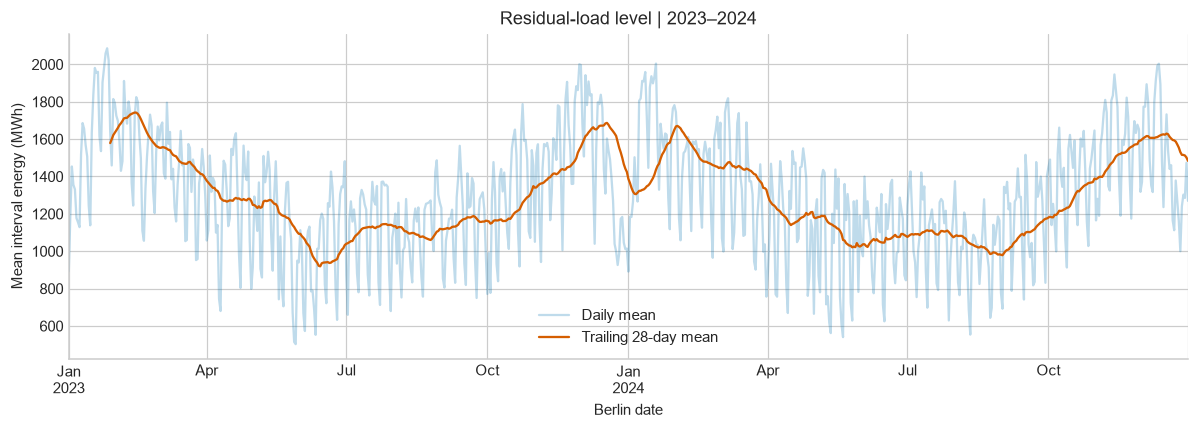

In [25]:
fig, ax = plt.subplots()
daily.plot(ax=ax, alpha=.25, label='Daily mean')
daily.rolling(28, min_periods=28).mean().plot(ax=ax, color=COLORS[1], label='Trailing 28-day mean')
ax.set(title='Residual-load level | 2023–2024', xlabel='Berlin date', ylabel='Mean interval energy (MWh)')
ax.legend()
fig.tight_layout()
fig.savefig('time_plots_rolling_mean.png', dpi=160, bbox_inches='tight')
plt.show()

### 5.3 Rolling variability

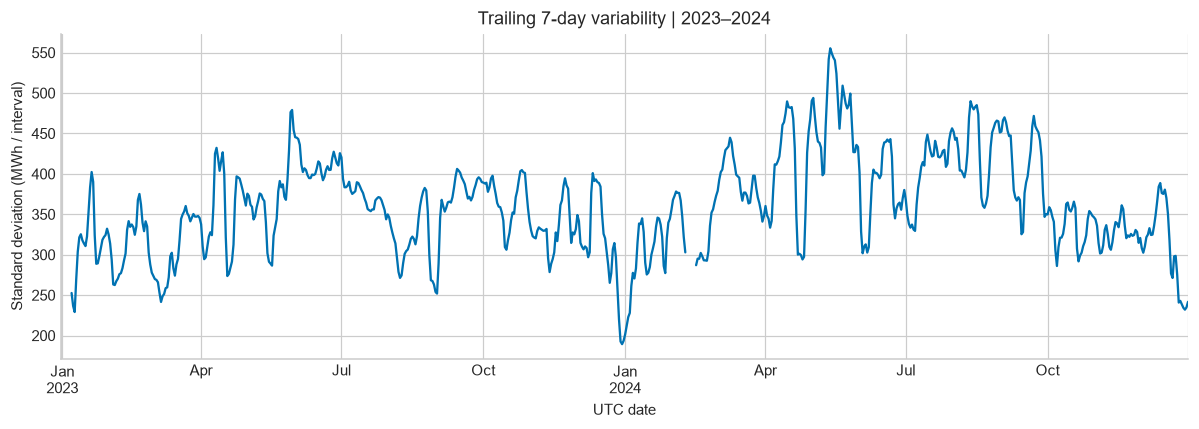

In [26]:
rolling_std = df['target'].rolling(96 * 7, min_periods=96 * 7).std()
fig, ax = plt.subplots()
rolling_std.resample('D').mean().plot(ax=ax, color=COLORS[0])
ax.set(title='Trailing 7-day variability | 2023–2024', xlabel='UTC date', ylabel='Standard deviation (MWh / interval)')
fig.tight_layout()
fig.savefig('time_plots_rolling_variability.png', dpi=160, bbox_inches='tight')
plt.show()

### 5.4 Representative weeks

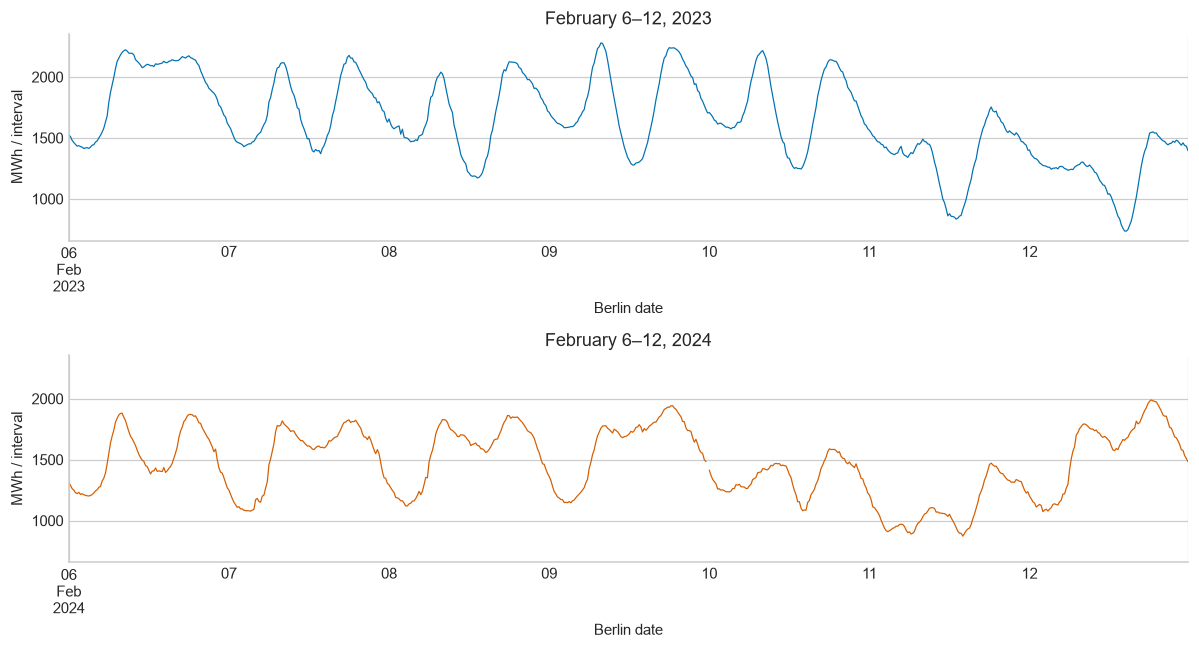

In [27]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharey=True)
for ax, year in zip(axes, YEARS):
    local_series = df['target'].tz_convert('Europe/Berlin')
    week = local_series.loc[f'{year}-02-06':f'{year}-02-12']
    week.plot(ax=ax, linewidth=.8, color=COLORS[YEARS.index(year)])
    ax.set(title=f'February 6–12, {year}', xlabel='Berlin date', ylabel='MWh / interval')
fig.tight_layout()
fig.savefig('time_plots_representative_weeks.png', dpi=160, bbox_inches='tight')
plt.show()

### Observations

Residual load is generally higher in winter and lower from late spring through summer. The rolling mean shows this seasonal cycle alongside a sharp interruption around Christmas and New Year. Daily residual load falls below 1,000 MWh around Christmas 2023 and New Year 2024, then approaches 1,900 MWh on several days in mid-January.

Reduced business and industrial activity over the holidays is a plausible contributor. [SMARD documents this holiday pattern in electricity consumption](https://www.smard.de/en/an-overview-of-the-electricity-market-at-christmas-206710). Weather and renewable generation also affect residual load, so the plots alone cannot attribute the dip to Christmas.

Variability is elevated for much of spring and summer 2024, even while the average level is low. The February examples also show pronounced daily ramps and lower weekend levels. The same calendar dates fall on different weekdays in the two years, which matters when comparing these short windows.

## 6. Seasonal profiles
### 6.1 Monthly profile

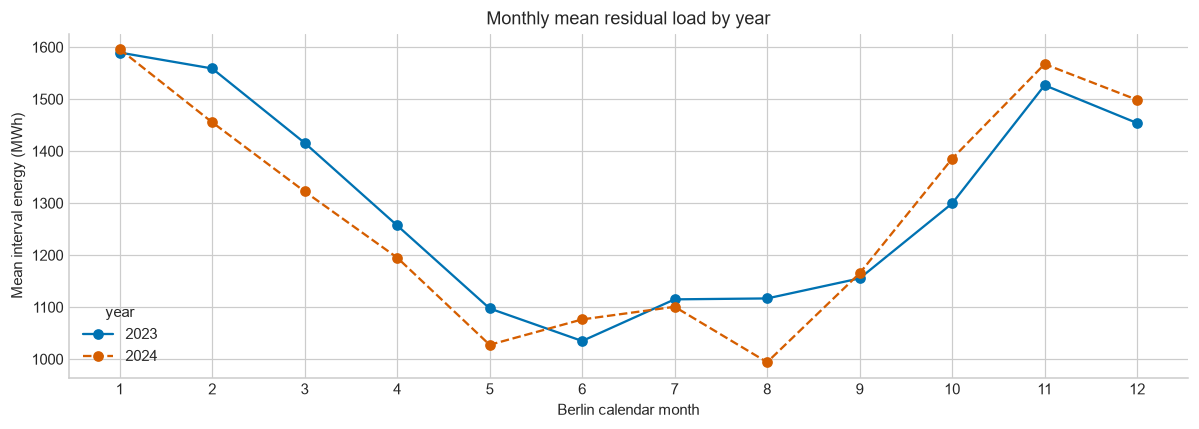

In [28]:
monthly = df.groupby(['month', 'year'])['target'].mean().unstack('year')
fig, ax = plt.subplots()
monthly.plot(ax=ax, marker='o', style=['-', '--'])
ax.set(title='Monthly mean residual load by year', xlabel='Berlin calendar month', ylabel='Mean interval energy (MWh)', xticks=range(1, 13))
fig.tight_layout()
fig.savefig('seasonal_profiles_monthly_profile.png', dpi=160, bbox_inches='tight')
plt.show()

### 6.2 Weekly profile

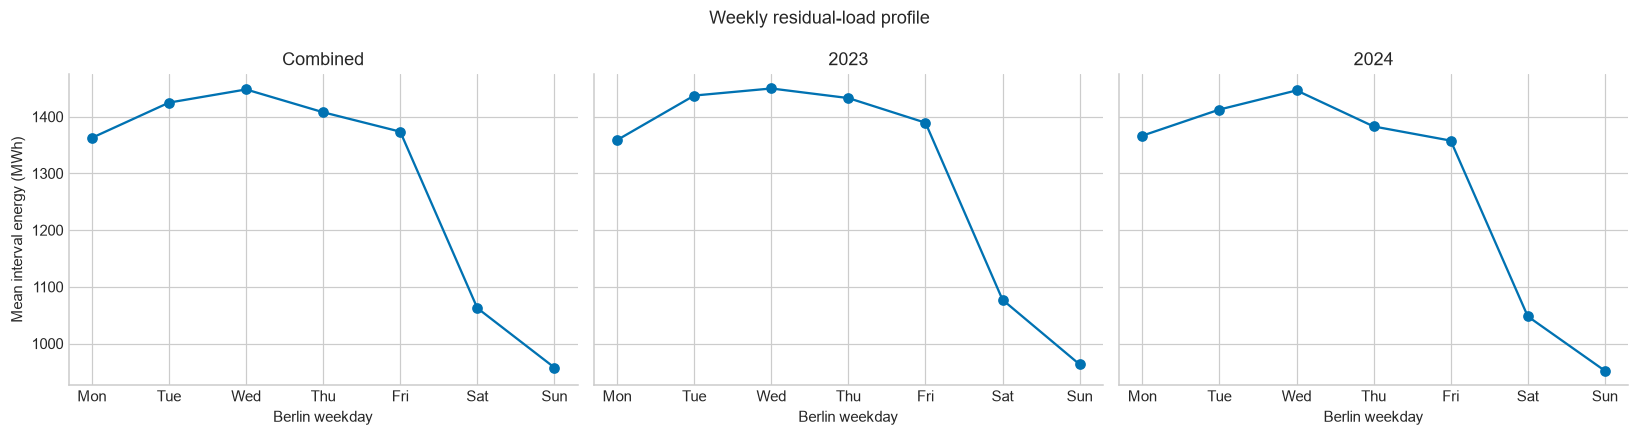

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, label, subset in [(axes[0], 'Combined', df), *[(axes[i + 1], str(year), df.loc[df['year'].eq(year)]) for i, year in enumerate(YEARS)]]:
    profile = subset.groupby('weekday')['target'].mean()
    ax.plot(profile.index, profile.values, marker='o')
    ax.set(title=label, xlabel='Berlin weekday', xticks=range(7), xticklabels=['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
axes[0].set_ylabel('Mean interval energy (MWh)')
fig.suptitle('Weekly residual-load profile')
fig.tight_layout()
fig.savefig('seasonal_profiles_weekly_profile.png', dpi=160, bbox_inches='tight')
plt.show()

### 6.3 Daily profile

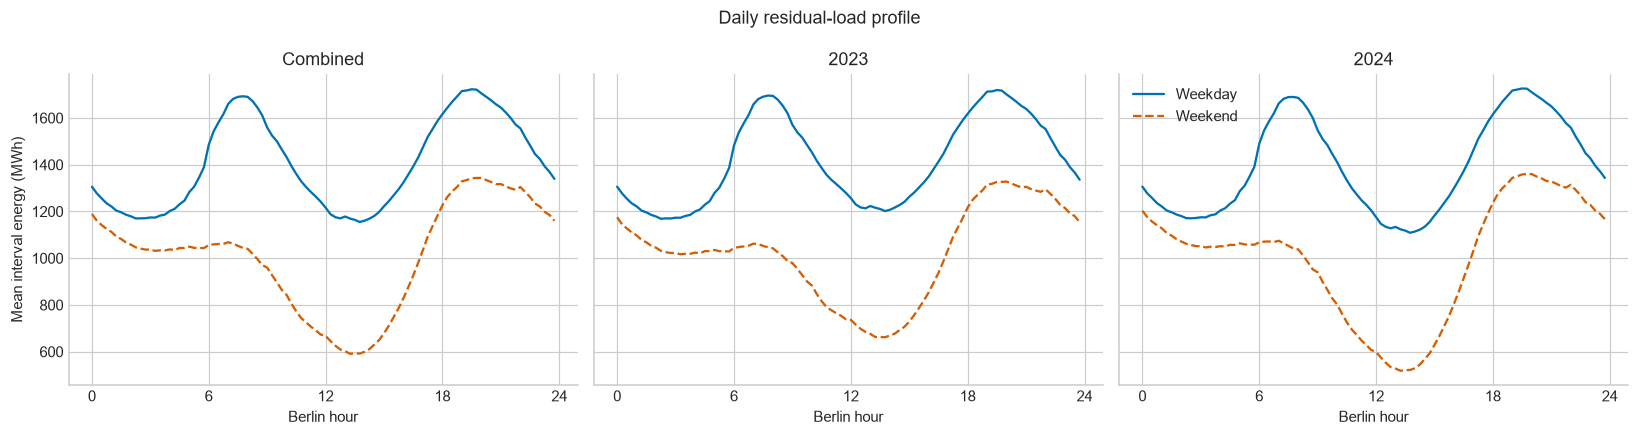

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, label, subset in [(axes[0], 'Combined', df), *[(axes[i + 1], str(year), df.loc[df['year'].eq(year)]) for i, year in enumerate(YEARS)]]:
    for weekend, name, style in [(False, 'Weekday', '-'), (True, 'Weekend', '--')]:
        profile = subset.loc[subset['weekday'].ge(5).eq(weekend)].groupby('quarter_hour')['target'].mean()
        ax.plot(profile.index, profile.values, style, label=name)
    ax.set(title=label, xlabel='Berlin hour', xticks=[0, 6, 12, 18, 24])
axes[0].set_ylabel('Mean interval energy (MWh)')
axes[-1].legend()
fig.suptitle('Daily residual-load profile')
fig.tight_layout()
fig.savefig('seasonal_profiles_daily_profile.png', dpi=160, bbox_inches='tight')
plt.show()

### 6.4 Holiday profile

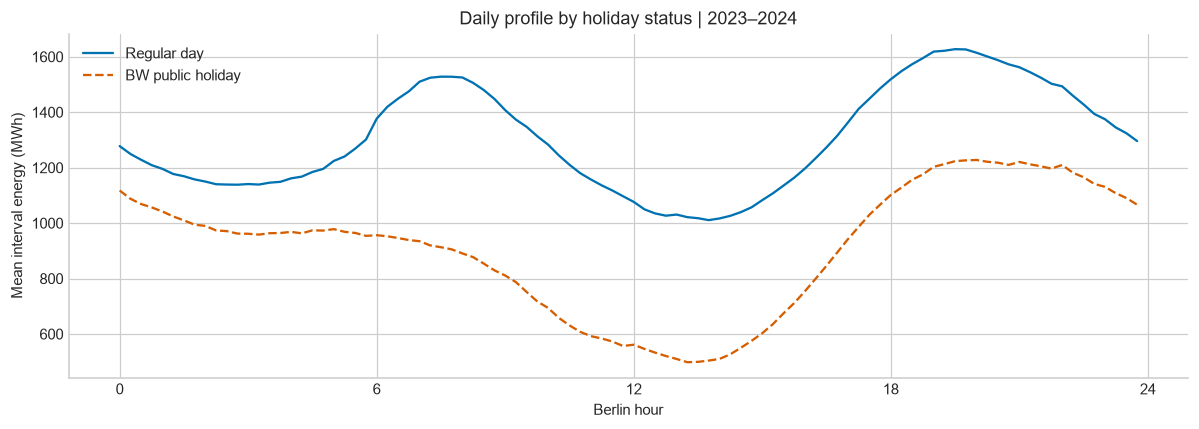

Holiday and regular-day groups have different weekday and seasonal compositions. This comparison is descriptive.


In [31]:
fig, ax = plt.subplots()
for holiday, label, style in [(0, 'Regular day', '-'), (1, 'BW public holiday', '--')]:
    profile = df.loc[df['is_holiday'].eq(holiday)].groupby('quarter_hour')['target'].mean()
    ax.plot(profile.index, profile.values, style, label=label)
ax.set(title='Daily profile by holiday status | 2023–2024', xlabel='Berlin hour', ylabel='Mean interval energy (MWh)', xticks=[0, 6, 12, 18, 24])
ax.legend()
fig.tight_layout()
fig.savefig('seasonal_profiles_holiday_profile.png', dpi=160, bbox_inches='tight')
plt.show()
print('Holiday and regular-day groups have different weekday and seasonal compositions. This comparison is descriptive.')

### Observations

- **Annual pattern:** January has the highest monthly mean in both years, near 1,590 MWh per interval. The lowest month shifts from June 2023, around 1,035 MWh, to August 2024, around 994 MWh. December is lower than November in both years, consistent with the year-end dip visible in the time plots.
- **Weekly pattern:** Residual load is highest from Tuesday to Thursday and lowest on Sunday. The weekend mean is about 1,010 MWh, approximately 28% below the weekday mean of 1,403 MWh. Both years show this structure.
- **Daily pattern:** Weekdays have peaks around 08:00 and 19:00–20:00, separated by a midday trough. Weekend mornings have a much weaker peak, followed by a deep early-afternoon trough. At 13:00, weekend averages fall from about 666 MWh in 2023 to 522 MWh in 2024.
- **Holiday pattern:** Public holidays resemble weekends, with a weak morning rise and low midday residual load. The midday trough is consistent with solar generation reducing the remaining load, alongside differences in electricity demand. Seasonal composition and weather also differ between holiday and regular-day groups.

## 7. Box plots

### 7.1 Monthly distributions

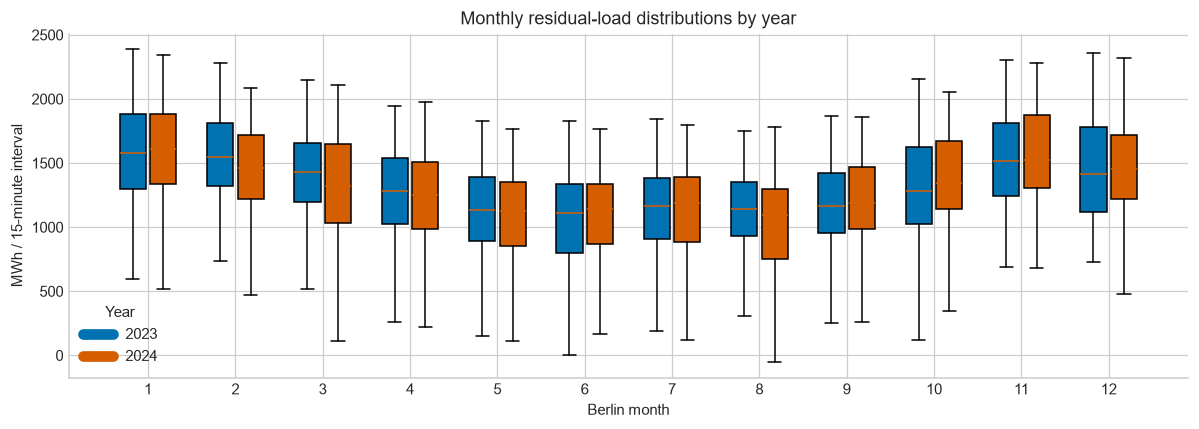

Boxes show median and interquartile range. Whiskers use 1.5 IQR. Outlier markers are hidden for readability and all observations remain in the calculations.


In [32]:
fig, ax = plt.subplots(figsize=(11, 4))
categories = sorted(df['month'].unique())
for year_index, year in enumerate(YEARS):
    groups = [df.loc[df['year'].eq(year) & df['month'].eq(category), 'target'].dropna() for category in categories]
    positions = np.arange(len(categories)) + (year_index - .5) * .35
    boxes = ax.boxplot(groups, positions=positions, widths=.3, showfliers=False, patch_artist=True, manage_ticks=False)
    for patch in boxes['boxes']:
        patch.set_facecolor(COLORS[year_index])
    ax.plot([], [], color=COLORS[year_index], linewidth=7, label=str(year))
ax.set_xticks(np.arange(len(categories)), categories)
ax.legend(title='Year')
ax.set(title='Monthly residual-load distributions by year', xlabel='Berlin month', ylabel='MWh / 15-minute interval')
fig.tight_layout()
fig.savefig('box_plots_monthly_distributions.png', dpi=160, bbox_inches='tight')
plt.show()
print('Boxes show median and interquartile range. Whiskers use 1.5 IQR. Outlier markers are hidden for readability and all observations remain in the calculations.')

### 7.2 Weekday distributions

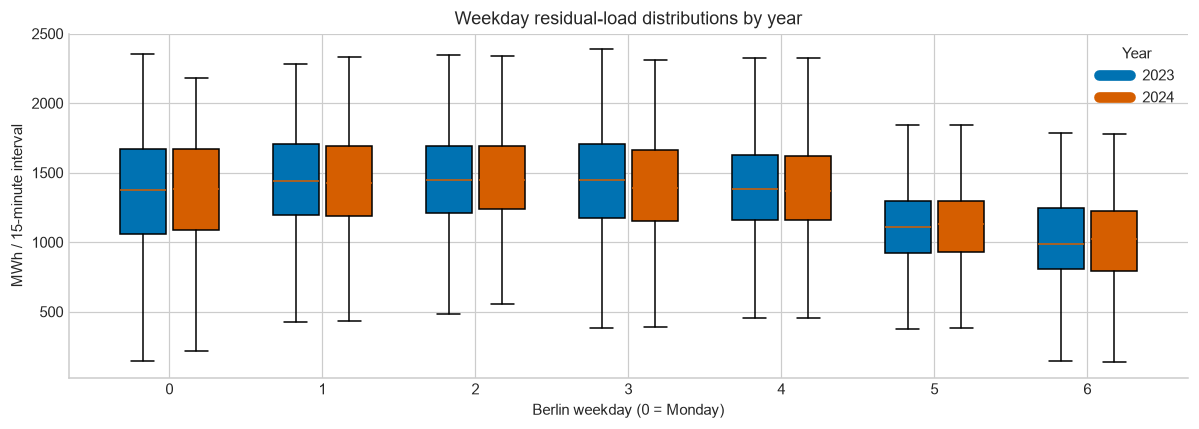

Boxes show median and interquartile range. Whiskers use 1.5 IQR. Outlier markers are hidden for readability and all observations remain in the calculations.


In [33]:
fig, ax = plt.subplots(figsize=(11, 4))
categories = sorted(df['weekday'].unique())
for year_index, year in enumerate(YEARS):
    groups = [df.loc[df['year'].eq(year) & df['weekday'].eq(category), 'target'].dropna() for category in categories]
    positions = np.arange(len(categories)) + (year_index - .5) * .35
    boxes = ax.boxplot(groups, positions=positions, widths=.3, showfliers=False, patch_artist=True, manage_ticks=False)
    for patch in boxes['boxes']:
        patch.set_facecolor(COLORS[year_index])
    ax.plot([], [], color=COLORS[year_index], linewidth=7, label=str(year))
ax.set_xticks(np.arange(len(categories)), categories)
ax.legend(title='Year')
ax.set(title='Weekday residual-load distributions by year', xlabel='Berlin weekday (0 = Monday)', ylabel='MWh / 15-minute interval')
fig.tight_layout()
fig.savefig('box_plots_weekday_distributions.png', dpi=160, bbox_inches='tight')
plt.show()
print('Boxes show median and interquartile range. Whiskers use 1.5 IQR. Outlier markers are hidden for readability and all observations remain in the calculations.')

### 7.3 Hourly distributions

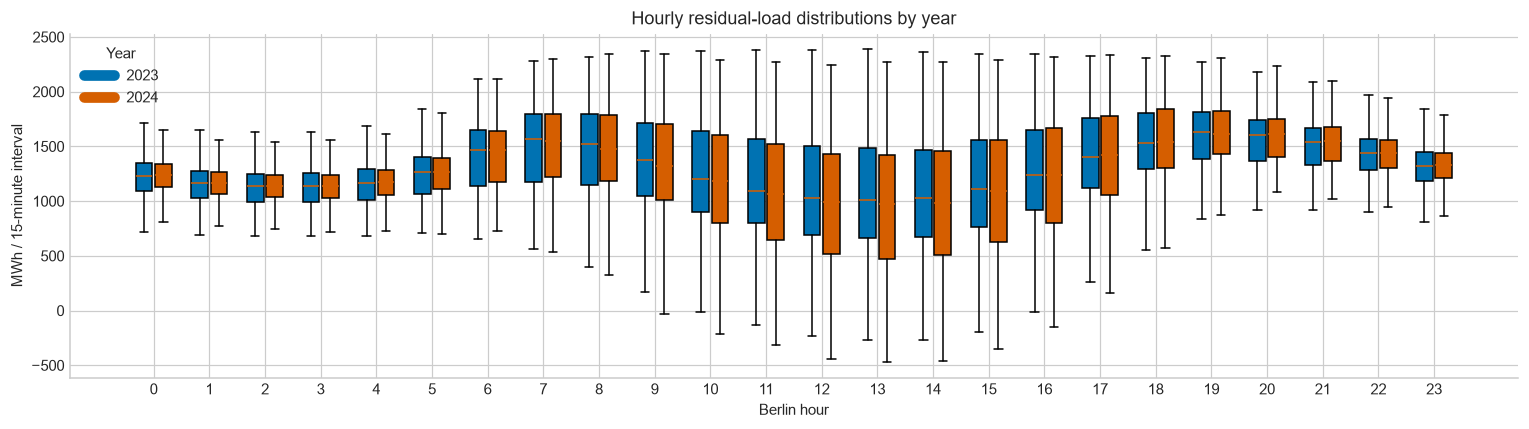

Boxes show median and interquartile range. Whiskers use 1.5 IQR. Outlier markers are hidden for readability and all observations remain in the calculations.


In [34]:
fig, ax = plt.subplots(figsize=(14, 4))
categories = sorted(df['hour'].unique())
for year_index, year in enumerate(YEARS):
    groups = [df.loc[df['year'].eq(year) & df['hour'].eq(category), 'target'].dropna() for category in categories]
    positions = np.arange(len(categories)) + (year_index - .5) * .35
    boxes = ax.boxplot(groups, positions=positions, widths=.3, showfliers=False, patch_artist=True, manage_ticks=False)
    for patch in boxes['boxes']:
        patch.set_facecolor(COLORS[year_index])
    ax.plot([], [], color=COLORS[year_index], linewidth=7, label=str(year))
ax.set_xticks(np.arange(len(categories)), categories)
ax.legend(title='Year')
ax.set(title='Hourly residual-load distributions by year', xlabel='Berlin hour', ylabel='MWh / 15-minute interval')
fig.tight_layout()
fig.savefig('box_plots_hourly_distributions.png', dpi=160, bbox_inches='tight')
plt.show()
print('Boxes show median and interquartile range. Whiskers use 1.5 IQR. Outlier markers are hidden for readability and all observations remain in the calculations.')

### Observations

The box plots show that the lower weekend level is visible in the middle of the distribution and persists across both years. Sunday medians are around 1,000 MWh per interval, while midweek medians are closer to 1,450 MWh.

Hourly dispersion is much wider around midday than overnight. In 2024, the midday boxes extend further down, while evening distributions remain comparatively close to 2023. This places much of the year-to-year difference in the daytime trough. Monthly distributions still overlap substantially, so season and hour describe broad patterns while leaving considerable interval-level variation.

## 8. Observations

Yearly averages and monthly peaks describe changes in residual-load levels across the development period.

In [20]:
means = df.groupby('year')['target'].mean()
monthly_peak = monthly.idxmax()
display(Markdown(f'The mean residual load is **{means.loc[2023]:,.1f} MWh per interval in 2023** and **{means.loc[2024]:,.1f} MWh per interval in 2024**. The highest monthly mean occurs in month **{int(monthly_peak.loc[2023])}** in 2023 and month **{int(monthly_peak.loc[2024])}** in 2024. These two years support a descriptive annual comparison. The dynamics notebook examines daily and weekly persistence.'))

The mean residual load is **1,300.2 MWh per interval in 2023** and **1,281.4 MWh per interval in 2024**. The highest monthly mean occurs in month **1** in 2023 and month **1** in 2024. These two years support a descriptive annual comparison. The dynamics notebook examines daily and weekly persistence.

## 9. Conclusions and modelling implications

Residual load has a recurring calendar structure across both development years. Winter levels are generally higher, weekends average about 28% below weekdays, and weekday profiles show morning and evening peaks separated by a midday trough. These patterns support forecasting approaches that can represent daily and weekly seasonality alongside slower changes through the year.

The similar yearly averages conceal a deeper midday trough, greater variability, and more negative intervals in 2024. Forecast evaluation should therefore examine performance across hours, day types, and seasons, since an overall score can conceal difficulties during low-residual-load periods. Negative values are part of the observed target range and should remain within the model's forecasting capability.

The Christmas–New Year dip suggests that special-day behaviour can interrupt the usual winter pattern. Reduced economic activity is a plausible contributor, while weather and renewable output also affect the remaining load. Two years provide evidence of recurring patterns and meaningful differences, with limited replication for judging their longer-term stability.